In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from skimage import data
from skimage.feature import local_binary_pattern

In [2]:
img = data.camera(); print("Image shape:", img.shape)

Image shape: (512, 512)


In [3]:
def lbp_pixel(img,i,j):                     # LBP of ONE pixel (the logic)
    c = img[i,j]
    nb = [img[i-1,j-1],img[i-1,j],img[i-1,j+1],img[i,j+1],
          img[i+1,j+1],img[i+1,j],img[i+1,j-1],img[i,j-1]]
    bits = "".join("1" if v >= c else "0" for v in nb)
    return bits, int(bits,2)
print("LBP of pixel (100,100):", lbp_pixel(img,100,100))

LBP of pixel (100,100): ('11011111', 223)


In [4]:
lbp = local_binary_pattern(img, P=8, R=1, method="uniform")   # whole image
bins = int(lbp.max()+1)
hist,_ = np.histogram(lbp, bins=bins, range=(0,bins), density=True)

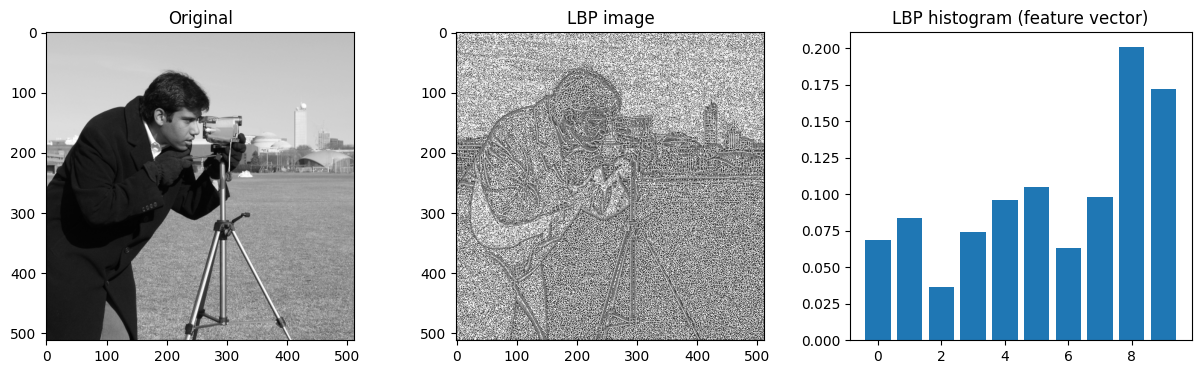

In [5]:
fig,ax = plt.subplots(1,3,figsize=(15,4))
ax[0].imshow(img,cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(lbp,cmap="gray"); ax[1].set_title("LBP image")
ax[2].bar(range(bins),hist); ax[2].set_title("LBP histogram (feature vector)")
plt.show()